# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Лавренюк Артем Дмитрович
**Група:** ФІТ 4-10  
**Дата:** 25.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)


TensorFlow: 2.21.0
NumPy: 2.4.6


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка/топ", "Штани", "Светр", "Сукня", "Пальто",
    "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"
]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print("Кількість класів:", len(class_names))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

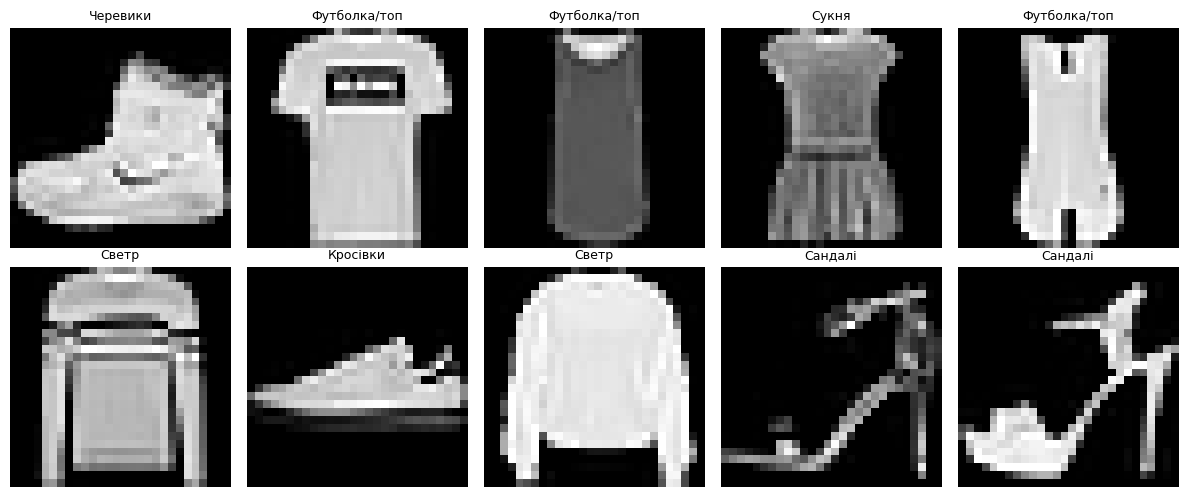

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[int(y_train[i])], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

print("Тип навчальних даних:", x_train_norm.dtype)
print("Тип тестових даних:", x_test_norm.dtype)
print("Діапазон навчальних даних:",
      float(x_train_norm.min()), "—", float(x_train_norm.max()))
print("Діапазон тестових даних:",
      float(x_test_norm.min()), "—", float(x_test_norm.max()))


Тип навчальних даних: float32
Тип тестових даних: float32
Діапазон навчальних даних: 0.0 — 1.0
Діапазон тестових даних: 0.0 — 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(10, activation="softmax")
])

LEARNING_RATE_1 = 0.001
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE_1),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Модель успішно створена та скомпільована.")
print(
    "Обґрунтування: 256 і 128 нейронів дають змогу моделі вивчати "
    "ознаки різної складності. Dropout 0.30 і 0.20 зменшує ризик "
    "перенавчання. Adam зі швидкістю навчання 0.001 забезпечує "
    "стабільне початкове навчання."
)


Модель успішно створена та скомпільована.
Обґрунтування: 256 і 128 нейронів дають змогу моделі вивчати ознаки різної складності. Dropout 0.30 і 0.20 зменшує ризик перенавчання. Adam зі швидкістю навчання 0.001 забезпечує стабільне початкове навчання.


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping_1 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)
reduce_lr_1 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_1 = model.fit(
    x_train_norm,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping_1, reduce_lr_1],
    verbose=1
)
epochs_1 = len(history_1.history["loss"])
print("Фактична кількість епох:", epochs_1)


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.7767 - loss: 0.6252 - val_accuracy: 0.8388 - val_loss: 0.4339 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8411 - loss: 0.4372 - val_accuracy: 0.8567 - val_loss: 0.3882 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8572 - loss: 0.3939 - val_accuracy: 0.8633 - val_loss: 0.3703 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8641 - loss: 0.3697 - val_accuracy: 0.8655 - val_loss: 0.3617 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8703 - loss: 0.3518 - val_accuracy: 0.8773 - val_loss: 0.3384 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8744 - loss: 0.3409 - val_accuracy: 0.8760 - val_loss: 0.3386 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8776 - loss: 0.3302

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
MODEL_1_PATH = "fashion_mnist_baran_model.keras"
model.save(MODEL_1_PATH)
print("Навчену модель збережено у файл:", MODEL_1_PATH)


Навчену модель збережено у файл: fashion_mnist_baran_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

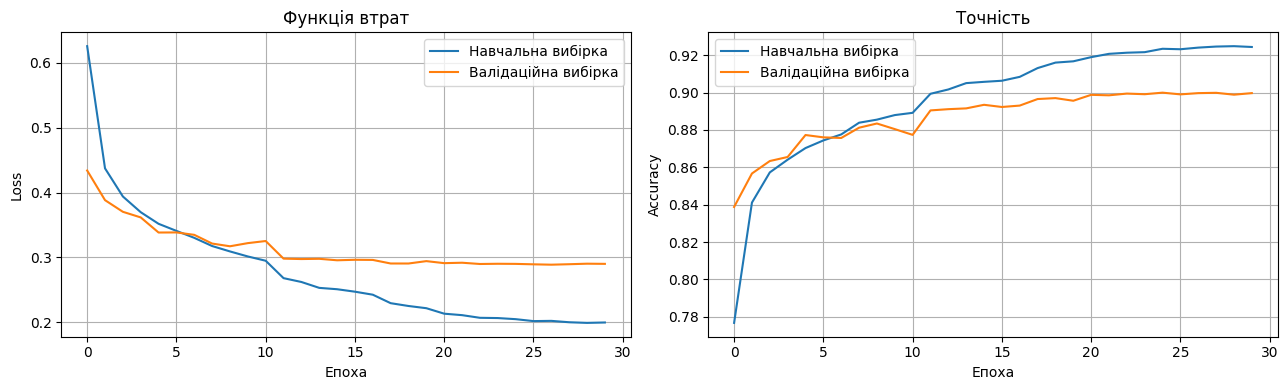

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_1.history["loss"], label="Навчальна вибірка")
axes[0].plot(history_1.history["val_loss"], label="Валідаційна вибірка")
axes[0].set_title("Функція втрат")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_1.history["accuracy"], label="Навчальна вибірка")
axes[1].plot(history_1.history["val_accuracy"], label="Валідаційна вибірка")
axes[1].set_title("Точність")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss_1, test_accuracy_1 = model.evaluate(
    x_test_norm, y_test, verbose=0
)
probabilities_1 = model.predict(x_test_norm, verbose=0)
y_pred_1 = np.argmax(probabilities_1, axis=1)

print(f"Тестова функція втрат (loss): {test_loss_1:.4f}")
print(f"Тестова точність (accuracy): {test_accuracy_1:.4f}")
print("Вимогу accuracy >= 0.87 виконано:", test_accuracy_1 >= 0.87)

print("\nКласифікаційний звіт:")
print(classification_report(
    y_test,
    y_pred_1,
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm_1 = confusion_matrix(y_test, y_pred_1)
errors_by_class_1 = cm_1.sum(axis=1) - np.diag(cm_1)
print("Кількість помилок за класами:")
for class_index in np.argsort(errors_by_class_1)[::-1]:
    print(f"{class_names[class_index]}: {errors_by_class_1[class_index]}")


Тестова функція втрат (loss): 0.3157
Тестова точність (accuracy): 0.8963
Вимогу accuracy >= 0.87 виконано: True

Класифікаційний звіт:
              precision    recall  f1-score   support

Футболка/топ     0.8482    0.8550    0.8516      1000
       Штани     0.9888    0.9740    0.9814      1000
       Светр     0.7979    0.8210    0.8093      1000
       Сукня     0.8963    0.9080    0.9021      1000
      Пальто     0.8158    0.8240    0.8199      1000
     Сандалі     0.9768    0.9700    0.9734      1000
     Сорочка     0.7450    0.7100    0.7271      1000
    Кросівки     0.9442    0.9650    0.9545      1000
       Сумка     0.9790    0.9780    0.9785      1000
    Черевики     0.9696    0.9580    0.9638      1000

    accuracy                         0.8963     10000
   macro avg     0.8962    0.8963    0.8962     10000
weighted avg     0.8962    0.8963    0.8962     10000

Кількість помилок за класами:
Сорочка: 290
Светр: 179
Пальто: 176
Футболка/топ: 145
Сукня: 92
Черевики: 42

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

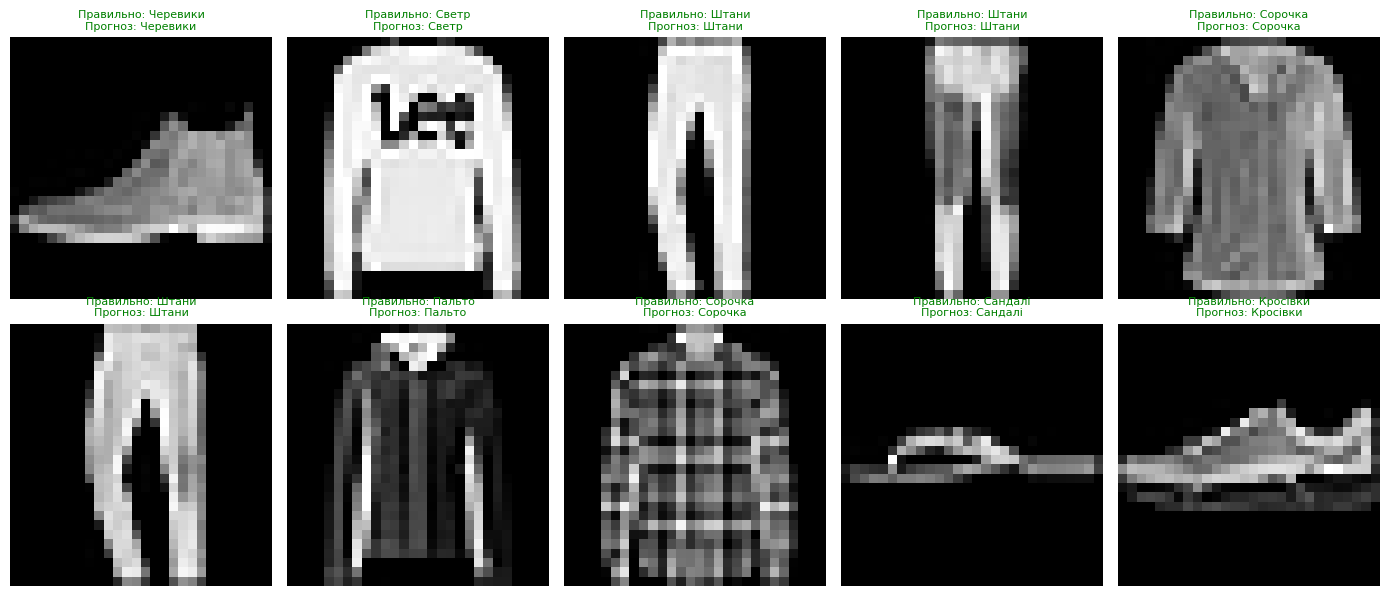

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(14, 6))
for i in range(10):
    true_label = int(y_test[i])
    predicted_label = int(y_pred_1[i])
    title_color = "green" if true_label == predicted_label else "red"

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Правильно: {class_names[true_label]}\n"
        f"Прогноз: {class_names[predicted_label]}",
        color=title_color,
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
**Ваш висновок:**  
Під час виконання першого завдання було створено та навчено нейронну мережу для класифікації зображень Fashion MNIST. Було виконано нормалізацію даних, побудовано графіки навчання та перевірено якість моделі на тестовій вибірці. Значення точності й класи, для яких модель припускається найбільшої кількості помилок, наведені у результатах виконання комірки оцінювання. За отриманим значенням accuracy можна визначити, чи досягнуто встановленого порога 0,87.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
%pip -q install -U keras-tuner

import keras_tuner as kt
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras import regularizers

print("Keras Tuner:", kt.__version__)


Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
x_tuner_train = x_train_norm
y_tuner_train = y_train

print("Дані для пошуку гіперпараметрів:")
print("x_tuner_train:", x_tuner_train.shape)
print("y_tuner_train:", y_tuner_train.shape)
print("Тестова вибірка не використовується під час пошуку.")


Дані для пошуку гіперпараметрів:
x_tuner_train: (60000, 28, 28)
y_tuner_train: (60000,)
Тестова вибірка не використовується під час пошуку.


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    tuned_model = keras.Sequential(name="fashion_mnist_tuned")
    tuned_model.add(layers.Input(shape=(28, 28)))
    tuned_model.add(Flatten())

    hidden_layers = hp.Int(
        "num_hidden_layers", min_value=1, max_value=3, step=1
    )
    l2_value = hp.Choice("l2", values=[1e-4, 1e-3, 1e-2])

    for layer_index in range(hidden_layers):
        units = hp.Int(
            f"units_{layer_index}",
            min_value=32,
            max_value=512,
            step=32
        )
        dropout_rate = hp.Float(
            f"dropout_{layer_index}",
            min_value=0.1,
            max_value=0.5,
            step=0.1
        )
        tuned_model.add(Dense(
            units,
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_value)
        ))
        tuned_model.add(Dropout(dropout_rate))

    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.01, 0.001, 0.0001]
    )
    tuned_model.add(Dense(10, activation="softmax"))

    tuned_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return tuned_model

print("Функцію build_model(hp) створено.")


Функцію build_model(hp) створено.


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="keras_tuner_results_baran",
    project_name="fashion_mnist",
    overwrite=True,
    seed=SEED
)

tuner.search_space_summary()


Search space summary
Default search space size: 5
num_hidden_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
early_stopping_tuner = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)
reduce_lr_tuner = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

tuner.search(
    x_tuner_train,
    y_tuner_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping_tuner, reduce_lr_tuner],
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
for parameter_name, parameter_value in best_hp.values.items():
    print(f"{parameter_name}: {parameter_value}")

print("\nСтруктура найкращої моделі з пошуку:")
tuner.get_best_models(num_models=1)[0].summary()

# Повторне навчання найкращої конфігурації зі збереженням history.
best_model = build_model(best_hp)
early_stopping_best = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)
reduce_lr_best = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_2 = best_model.fit(
    x_tuner_train,
    y_tuner_train,
    epochs=25,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping_best, reduce_lr_best],
    verbose=1
)
epochs_2 = len(history_2.history["loss"])
print("Фактична кількість епох після налаштування:", epochs_2)


Trial 3 Complete [00h 01m 59s]
val_accuracy: 0.8955000042915344

Best val_accuracy So Far: 0.8955000042915344
Total elapsed time: 00h 03m 45s
Найкращі гіперпараметри:
num_hidden_layers: 3
l2: 0.0001
units_0: 512
dropout_0: 0.1
learning_rate: 0.001
units_1: 128
dropout_1: 0.2
units_2: 32
dropout_2: 0.1

Структура найкращої моделі з пошуку:


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "fashion_mnist_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 472,042 (1.80 MB)

 Trainable params: 472,042 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7691 - loss: 0.7223 - val_accuracy: 0.8482 - val_loss: 0.5111 - learning_rate: 0.0010
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8440 - loss: 0.5121 - val_accuracy: 0.8603 - val_loss: 0.4561 - learning_rate: 0.0010
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8587 - loss: 0.4645 - val_accuracy: 0.8691 - val_loss: 0.4431 - learning_rate: 0.0010
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8695 - loss: 0.4367 - val_accuracy: 0.8748 - val_loss: 0.4183 - learning_rate: 0.0010
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8737 - loss: 0.4209 - val_accuracy: 0.8731 - val_loss: 0.4193 - learning_rate: 0.0010
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8780 - loss: 0.4090 - val_accuracy: 0.8743 - val_loss: 0.4101 - learning_rate: 0.0010
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8831 - loss: 0.

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Тестова функція втрат (loss): 0.3733
Тестова точність (accuracy): 0.8933


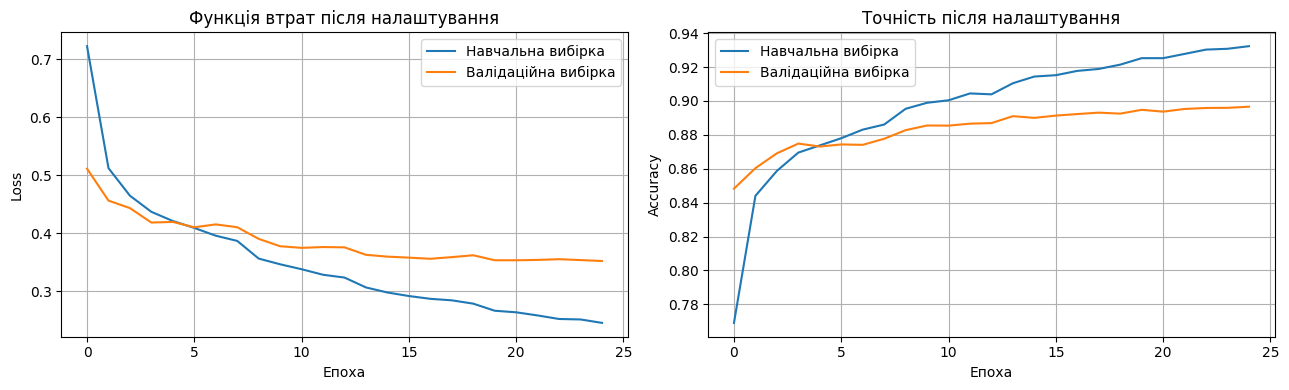

,Показник,Модель із завдання 1,Модель після Keras Tuner
0,Кількість прихованих шарів,2,3
1,Кількість нейронів,"[256, 128]","[512, 128, 32]"
2,Швидкість навчання,0.001,0.001
3,Точність на тестовій вибірці (accuracy),0.8963,0.8933
4,Втрати на тестовій вибірці (loss),0.3157,0.3733
5,Кількість епох навчання,30,25



Відповіді за результатами запуску:
1. Точність завдання 1 не нижче 0.87: True
2. Покращення accuracy після налаштування: False
3. Найкращі гіперпараметри: {'num_hidden_layers': 3, 'l2': 0.0001, 'units_0': 512, 'dropout_0': 0.1, 'learning_rate': 0.001, 'units_1': 128, 'dropout_1': 0.2, 'units_2': 32, 'dropout_2': 0.1}
4. Класи з найбільшою кількістю помилок у завданні 1:
Сорочка — 290
Светр — 179
Пальто — 176


In [17]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss_2, test_accuracy_2 = best_model.evaluate(
    x_test_norm, y_test, verbose=0
)
print(f"Тестова функція втрат (loss): {test_loss_2:.4f}")
print(f"Тестова точність (accuracy): {test_accuracy_2:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_2.history["loss"], label="Навчальна вибірка")
axes[0].plot(history_2.history["val_loss"], label="Валідаційна вибірка")
axes[0].set_title("Функція втрат після налаштування")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_2.history["accuracy"], label="Навчальна вибірка")
axes[1].plot(history_2.history["val_accuracy"], label="Валідаційна вибірка")
axes[1].set_title("Точність після налаштування")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

def hidden_dense_units(neural_model):
    return [
        layer.units for layer in neural_model.layers
        if isinstance(layer, keras.layers.Dense) and layer.units != 10
    ]

comparison_df = pd.DataFrame({
    "Показник": [
        "Кількість прихованих шарів",
        "Кількість нейронів",
        "Швидкість навчання",
        "Точність на тестовій вибірці (accuracy)",
        "Втрати на тестовій вибірці (loss)",
        "Кількість епох навчання"
    ],
    "Модель із завдання 1": [
        len(hidden_dense_units(model)),
        str(hidden_dense_units(model)),
        LEARNING_RATE_1,
        round(float(test_accuracy_1), 4),
        round(float(test_loss_1), 4),
        epochs_1
    ],
    "Модель після Keras Tuner": [
        len(hidden_dense_units(best_model)),
        str(hidden_dense_units(best_model)),
        best_hp.get("learning_rate"),
        round(float(test_accuracy_2), 4),
        round(float(test_loss_2), 4),
        epochs_2
    ]
})

display(comparison_df)

print("\nВідповіді за результатами запуску:")
print("1. Точність завдання 1 не нижче 0.87:", test_accuracy_1 >= 0.87)
print("2. Покращення accuracy після налаштування:", test_accuracy_2 > test_accuracy_1)
print("3. Найкращі гіперпараметри:", best_hp.values)
print("4. Класи з найбільшою кількістю помилок у завданні 1:")
for class_index in np.argsort(errors_by_class_1)[::-1][:3]:
    print(class_names[int(class_index)], "—", int(errors_by_class_1[class_index]))


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |  |  |
| Кількість нейронів |  |  |
| Швидкість навчання |  |  |
| Точність на тестовій вибірці (accuracy) |  |  |
| Втрати на тестовій вибірці (loss) |  |  |
| Кількість епох навчання |  |  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
**Власні висновки:**  
У другому завданні було використано Keras Tuner для автоматичного пошуку кращої конфігурації нейронної мережі методом RandomSearch. Після пошуку найкращі гіперпараметри були використані для повторного навчання моделі. Результати двох моделей порівнюються за точністю, функцією втрат, кількістю прихованих шарів, нейронів і епох. Остаточний висновок щодо покращення якості зроблено на основі отриманих значень тестової accuracy та loss. Також під час роботи було помітно, що різні класи одягу розпізнаються з різною точністю.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.